# 1. Introdução

Este notebook tem como objetivo explorar a biblioteca **pytrendseries**, uma ferramenta Python para detecção de tendências em séries temporais financeiras.

**Objetivo:**
- Demonstrar como utilizar a biblioteca para analisar dados históricos de ativos.
- Calcular e interpretar todas as métricas disponíveis (Drawdown, Time Under Water, etc.).
- Entender como os parâmetros afetam a detecção de tendências.

**Métricas que serão exploradas:**
- Detecção de tendências de alta (uptrend) e baixa (downtrend).
- Rotulagem para Machine Learning (Labels).
- Máximo Drawdown (Max Drawdown).
- Drawdown Atual (Current Drawdown).
- Tempo Submerso (Time Under Water).

# 2. Imports

Vamos importar as bibliotecas necessárias para manipulação de dados, visualização e a própria `pytrendseries`.

**Nota:** Se não tiver as bibliotecas instaladas, execute no terminal: `pip install pytrendseries yfinance matplotlib pandas`

In [1]:
import matplotlib.pyplot as plt
import yfinance as yf

import pytrendseries

# Configuração para gráficos maiores
plt.rcParams["figure.figsize"] = (14, 6)
plt.style.use("fivethirtyeight")

0.1.11


# 3. Download dos dados

Vamos baixar os dados históricos dos últimos 5 anos de um ativo (por padrão PETR4.SA). 
**Altere a variável `TICKER` abaixo para analisar outro ativo.**

In [2]:
# CONFIGURAÇÃO DO ATIVO
TICKER = "PETR4.SA"
PERIOD = "5y"

# Download dos dados
print(f"Baixando dados de {TICKER} para os últimos {PERIOD}...")
data = yf.download(TICKER, period=PERIOD)

# Preparar o DataFrame para a pytrendseries
# A biblioteca exige que o DataFrame tenha apenas UMA coluna numérica e um DatetimeIndex.
# Portanto, renomeamos a coluna para 'close_price' para atender a esse requisito.
df_prices = data[["Close"]].copy()
df_prices.columns = ["close_price"]

print("\nEstatísticas básicas:")
display(df_prices.describe())

Baixando dados de PETR4.SA para os últimos 5y...


[*********************100%***********************]  1 of 1 completed


Estatísticas básicas:


,close_price
count,1248.00000
mean,23.99917
std,10.11082
min,7.51856
25%,14.05504
50%,27.06415
75%,30.09319
max,48.52372


# 4. Visualização da Série Temporal

Vamos plotar o preço de fechamento para ter uma ideia visual do comportamento do ativo.

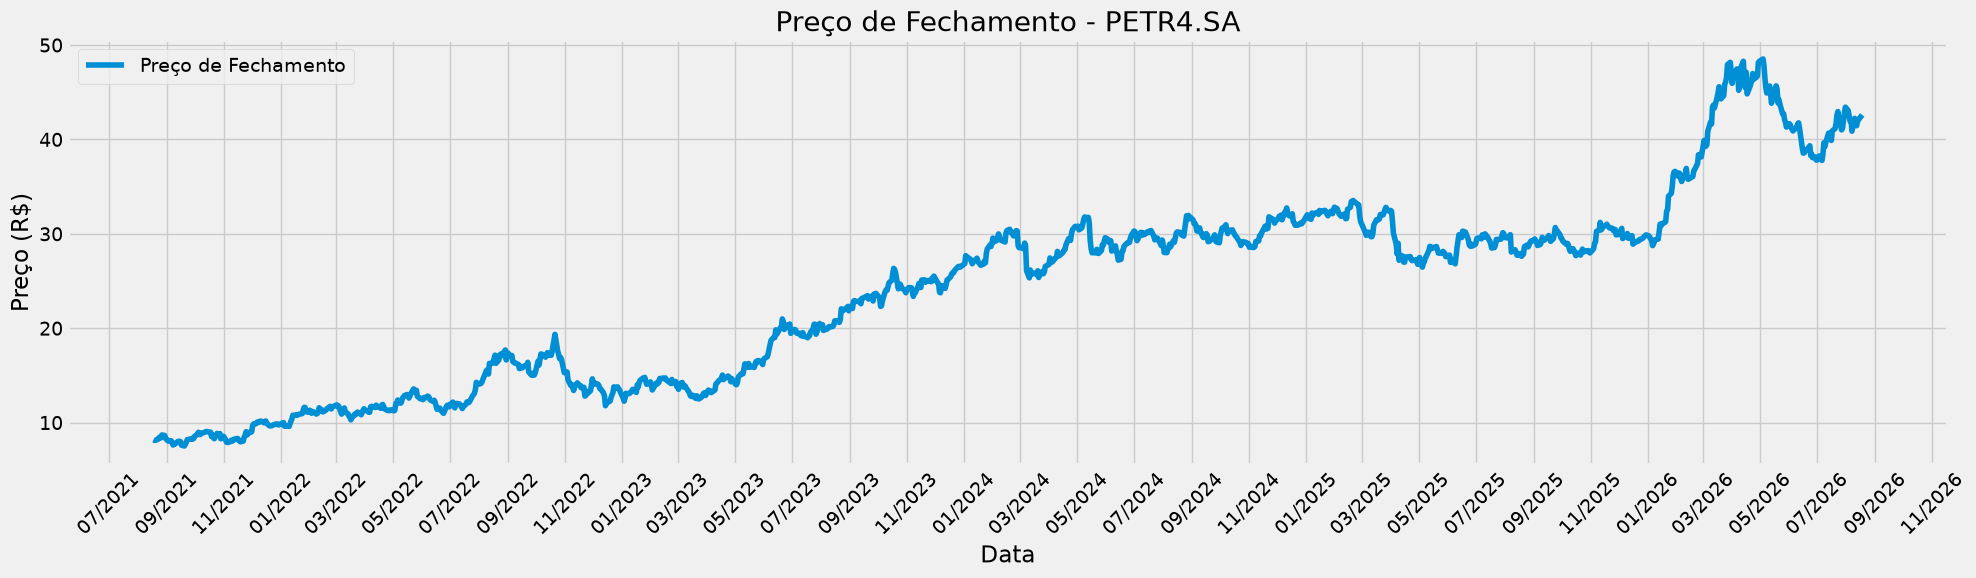

In [3]:
import matplotlib.dates as mdates

plt.figure(figsize=(20, 6))
plt.plot(df_prices.index, df_prices["close_price"], label="Preço de Fechamento")

plt.title(f"Preço de Fechamento - {TICKER}")
plt.xlabel("Data")
plt.ylabel("Preço (R$)")

# Eixo X: marcações a cada 3 meses
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Detectando Downtrends

A função `detecttrend` identifica os movimentos de queda significativos. 

**Parâmetros importantes:**
- `trend='downtrend'`: Define que procuramos tendências de baixa.
- `window=21`: Janela máxima para considerar uma tendência (21 dias úteis ≈ 1 mês).
- `limit=5`: Mínimo de dias para ser considerado uma tendência válida.

In [4]:
# Detectar downtrends
trends_down = pytrendseries.detecttrend(
    df_prices, trend="downtrend", window=21, limit=5
)

print(f"Foram encontradas {len(trends_down)} tendências de baixa.")

# Mostrando o DataFrame completo conforme solicitado
# Para séries muito longas, considere usar .tail() ou .sample() se preferir
display(trends_down)

Trends detected in 0.01 secs
Foram encontradas 45 tendências de baixa.


,Peak Date,Valley Date,Peak,Valley,index_peak,index_valley,time_span,drawdown
1,2021-08-27,2021-09-20,8.68981,7.51856,7,22,15,0.13478
2,2021-10-14,2021-11-05,9.05278,7.88458,39,54,15,0.12904
3,2021-12-16,2022-01-10,10.17296,9.59733,82,97,15,0.05658
4,2022-01-27,2022-02-08,11.60862,10.90620,110,118,8,0.06051
5,2022-03-02,2022-03-17,11.87930,10.28260,132,143,11,0.13441
6,2022-04-20,2022-05-02,11.92010,11.23788,166,173,7,0.05723
7,2022-05-23,2022-06-21,13.56942,11.30767,188,208,20,0.16668
8,2022-07-04,2022-07-14,12.17235,11.48312,217,225,8,0.05662
9,2022-08-29,2022-09-26,17.68778,15.02538,257,276,19,0.15052
10,2022-10-21,2022-11-22,19.34986,12.80407,294,314,20,0.33829


### Interpretação das Colunas
- **Peak Date**: Data do topo antes da queda.
- **Valley Date**: Data do fundo do poço.
- **Peak / Valley**: Preços correspondentes.
- **drawdown**: Percentual de queda (ex: 0.10 = 10% de perda).
- **time_span**: Duração da queda em dias.

# 6. Detectando Uptrends

Agora vamos detectar as tendências de alta, invertendo o parâmetro `trend`.

In [5]:
# Detectar uptrends
trends_up = pytrendseries.detecttrend(df_prices, trend="uptrend", window=21, limit=5)

print(f"Foram encontradas {len(trends_up)} tendências de alta.")

# Mostrando o DataFrame completo conforme solicitado
# Para séries longas, considere usar .tail() ou .sample() se preferir
display(trends_up)

# Observação: A coluna de intensidade se chama 'drawup' para tendências de alta

Trends detected in 0.04 secs
Foram encontradas 55 tendências de alta.


,Valley Date,Peak Date,Valley,Peak,index_valley,index_peak,time_span,drawup
1,2021-08-20,2021-08-27,8.11334,8.68981,2,7,5,0.07105
2,2021-09-08,2021-09-15,7.61617,8.03099,14,19,5,0.05447
3,2021-09-20,2021-10-14,7.51856,9.05278,22,39,17,0.20406
4,2021-11-05,2021-12-06,7.88458,9.89885,54,74,20,0.25547
5,2021-12-06,2021-12-16,9.89885,10.17296,74,82,8,0.02769
6,2021-12-20,2022-01-04,9.64872,10.00506,84,93,9,0.03693
7,2022-01-10,2022-01-27,9.59733,11.60862,97,110,13,0.20957
8,2022-02-08,2022-03-02,10.90620,11.87930,118,132,14,0.08922
9,2022-03-17,2022-04-13,10.28260,11.84504,143,162,19,0.15195
10,2022-05-02,2022-05-23,11.23788,13.56942,173,188,15,0.20747


# 7. Labels para Machine Learning

A função `get_trends_labels` converte as tendências detectadas em rótulos (labels) para cada linha do DataFrame, sendo muito útil para treinar modelos de classificação.

**Valores padrão:**
- `1`: Uptrend
- `-1`: Downtrend
- `0`: Sem tendência (neutro)

In [ ]:
# # Gerar labels
# df_labeled = pytrendseries.get_trends_labels(df_prices.copy(), window=21, limit=5)

# print("Distribuição dos Labels:")
# print(df_labeled["label"].value_counts())

# display(df_labeled.head(10))

In [ ]:
# # Visualizar os labels no gráfico de preço
# plt.figure(figsize=(14, 6))

# # Cores para cada label
# colors = {-1: "red", 0: "gray", 1: "green"}

# for label in [-1, 0, 1]:
#     subset = df_labeled[df_labeled["label"] == label]
#     plt.scatter(
#         subset.index,
#         subset["close_price"],
#         color=colors[label],
#         label=f"Label {label}",
#         s=25,
#         alpha=0.6,
#     )

# plt.title(f"Visualização dos Labels - {TICKER}")
# plt.legend()
# plt.grid(True, alpha=0.3)
# plt.show()

# 8. Máximo Drawdown

O **Máximo Drawdown** é a maior queda percentual entre um pico e um vale subsequente, antes que um novo pico seja atingido. É uma medida clássica de risco.

In [7]:
# Calcular Max Drawdown global
max_dd = pytrendseries.maxdrawdown(df_prices, window=None)

print("Máximo Drawdown Global:")
display(max_dd)

if not max_dd.empty:
    print(f"\nO pior drawdown foi de {max_dd['MaxDD'].values[0] * 100:.2f}%")

MDD calculated in 0.007 seconds
Window Size: 1248 records | Total Windows Analyzed: 1
Drawdown Events Found: 1
Máximo Drawdown Global:


,Window Start,Window End,Peak Date,Valley Date,Peak,Valley,MaxDD,Time Span
0,2021-08-18,2026-08-18,2022-10-21,2022-12-14,19.34986,11.78326,0.39104,37



O pior drawdown foi de 39.10%


# 9. Current Drawdown

Esta função calcula o quanto o ativo está caindo *agora* em relação ao seu último pico histórico.

In [8]:
# Calcular Drawdown Atual
current_dd = pytrendseries.calculate_current_drawdown(df_prices)

print("Status Atual do Drawdown:")
display(current_dd)

Status Atual do Drawdown:


,current_price,last_peak,current_drawdown,last_peak_date,time_in_drawdown
0,42.60000,48.52372,-12.20788,2026-05-04,75


# 10. Time Under Water (TUW)

O **Time Under Water** mede o tempo (em dias) que o investidor levou para recuperar o capital investido após um drawdown. Se o investimento ainda não recuperou, o status é "Ongoing".

In [9]:
# Calcular Time Under Water
tuw = pytrendseries.calculate_time_under_water(df_prices)

print("Períodos submersos (Time Under Water):")
display(tuw)

TUW calculated in 0.010 seconds
Total drawdown periods: 60
  - Recovered: 59
  - Ongoing: 1
Períodos submersos (Time Under Water):


,Peak Date,Recovery Date,Peak,Valley,MaxDD,Time Underwater,Status
0,2022-10-21,2023-06-13,19.34986,11.78326,0.39104,158,Recovered
1,2026-05-04,NaT,48.52372,37.77000,0.22162,75,Ongoing
2,2025-02-20,2026-01-22,33.52608,26.46687,0.21056,229,Recovered
3,2022-05-23,2022-07-28,13.56942,10.98185,0.19069,47,Recovered
4,2024-02-19,2024-04-26,30.48582,25.33378,0.16900,48,Recovered
5,2022-08-29,2022-10-18,17.68778,15.01512,0.15110,34,Recovered
6,2024-05-09,2024-08-23,31.77900,27.20172,0.14403,75,Recovered
7,2021-08-27,2021-10-01,8.68981,7.51856,0.13478,24,Recovered
8,2022-03-02,2022-04-19,11.87930,10.28260,0.13441,33,Recovered
9,2021-10-14,2021-12-01,9.05278,7.88458,0.12904,32,Recovered


# 11. Visualizações da Biblioteca

A biblioteca possui funções prontas para plotar as tendências e drawdowns.
- `plot_trend`: Destaca os períodos de tendência (verde para alta, vermelho para baixa).
- `plot_evolution`: Mostra a evolução do preço e do pico acumulado.

**Nota:** As funções de plotagem da biblioteca já adicionam títulos e legendas automaticamente.

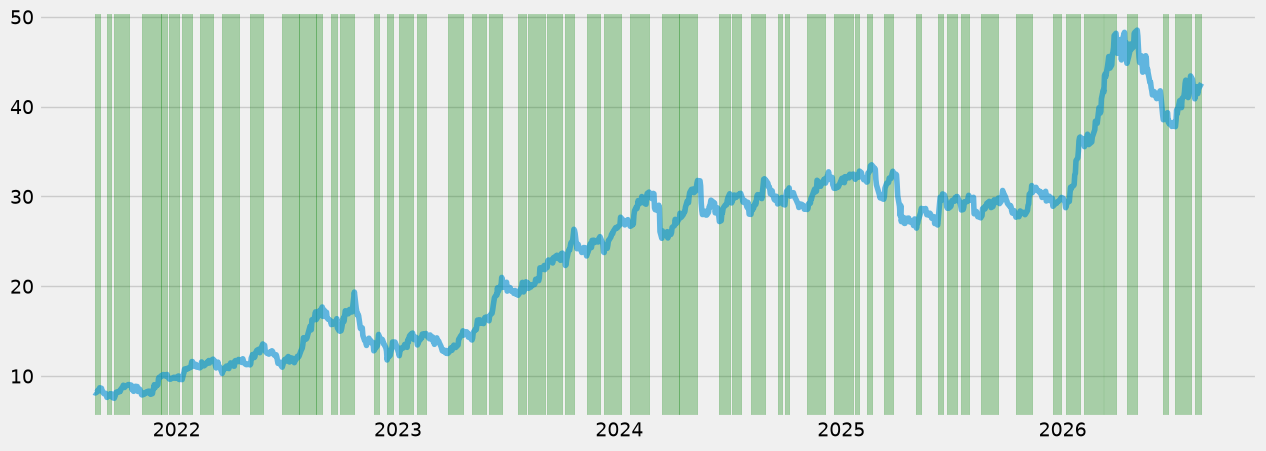

Plotted in 0.19 secs


In [10]:
# Plotar Tendências de Baixa encontradas
pytrendseries.vizplot.plot_trend(df_prices, trends_up, trend="uptrend")

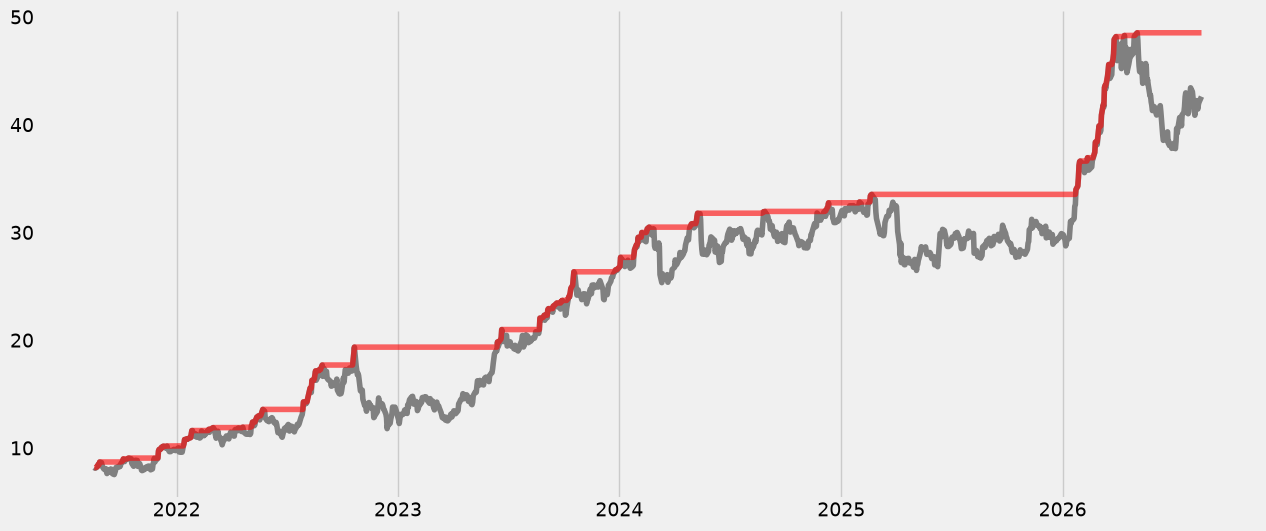

In [11]:
# Plotar Evolução do Drawdown
pytrendseries.vizplot.plot_evolution(df_prices, figsize=(14, 6))

# 12. Explorando Parâmetros

Vamos ver como a escolha dos parâmetros `window` e `limit` altera a sensibilidade da detecção.

**Qualidade do impacto:**
- Um **menor window** capta flutuações de curto prazo, gerando muitas tendências pequenas.
- Um **maior window** foca em movimentos mais amplos e de longo prazo.
- Um **maior limit** filtra ruídos, mantendo apenas quedas ou subidas significativas.
- Um **menor limit** permite que até mesmo pequenas oscilações sejam classificadas como tendências.

Trends detected in 0.02 secs
Trends detected in 0.02 secs
Trends detected in 0.01 secs
Trends detected in 0.01 secs
Trends detected in 0.01 secs


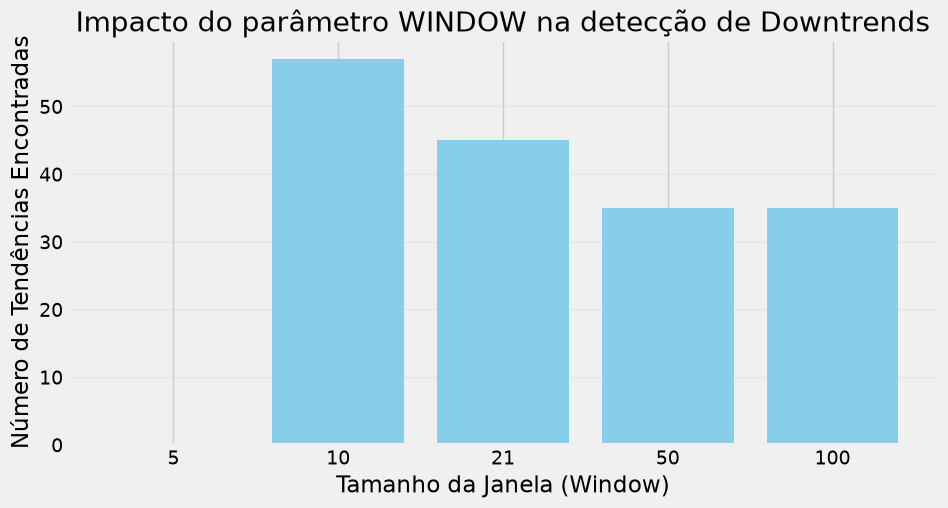

In [12]:
windows = [5, 10, 21, 50, 100]
results_window = []

for w in windows:
    trends = pytrendseries.detecttrend(df_prices, trend="downtrend", window=w, limit=5)
    results_window.append(len(trends))

plt.figure(figsize=(10, 5))
plt.bar([str(x) for x in windows], results_window, color="skyblue")
plt.title("Impacto do parâmetro WINDOW na detecção de Downtrends")
plt.xlabel("Tamanho da Janela (Window)")
plt.ylabel("Número de Tendências Encontradas")
plt.grid(axis="y", alpha=0.3)
plt.show()

Trends detected in 0.04 secs
Trends detected in 0.03 secs
Trends detected in 0.03 secs
Trends detected in 0.03 secs


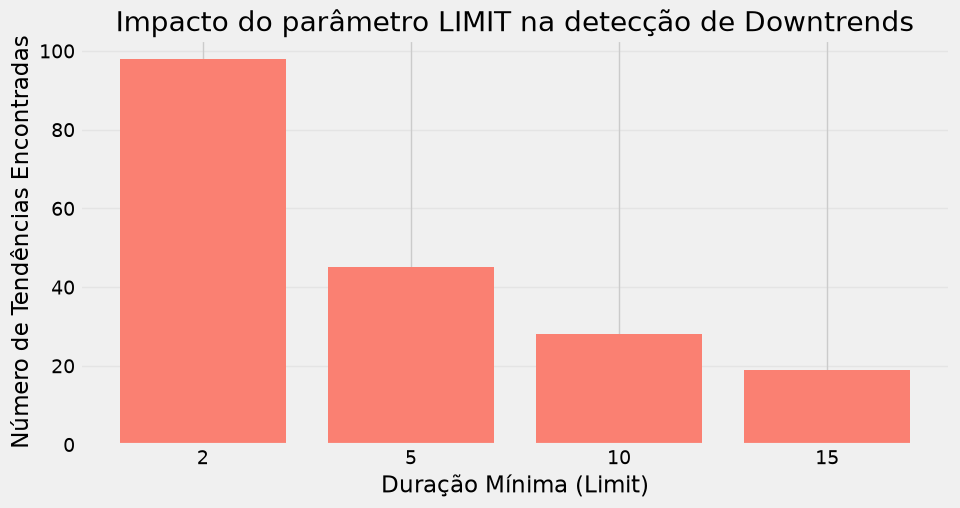

In [13]:
limits = [2, 5, 10, 15]
results_limit = []

for l in limits:
    trends = pytrendseries.detecttrend(df_prices, trend="downtrend", window=21, limit=l)
    results_limit.append(len(trends))

plt.figure(figsize=(10, 5))
plt.bar([str(x) for x in limits], results_limit, color="salmon")
plt.title("Impacto do parâmetro LIMIT na detecção de Downtrends")
plt.xlabel("Duração Mínima (Limit)")
plt.ylabel("Número de Tendências Encontradas")
plt.grid(axis="y", alpha=0.3)
plt.show()

# 13. Resumo Final

## Tabela de Funcionalidades

| Função | Objetivo | Entrada | Saída | Quando Utilizar |
|:---|:---|:---|:---|:---|
| `detecttrend` | Identificar movimentos de alta/baixa | DataFrame com preços | Lista de tendências | Para análise de ciclo de mercado |
| `get_trends_labels` | Gerar classes para ML | DataFrame com preços | DataFrame com coluna 'label' | Para treinar modelos de classificação |
| `maxdrawdown` | Calcular maior queda histórica | DataFrame com preços | Métrica de risco | Para avaliar risco máximo de perda |
| `calculate_current_drawdown` | Verificar estado atual | DataFrame com preços | Drawdown em % | Para monitoramento em tempo real |
| `calculate_time_under_water` | Tempo de recuperação | DataFrame com preços | Dias até recuperação | Para analisar resiliência do ativo |

## Conclusões

- **Funcionalidades:** O pytrendseries oferece um conjunto completo de ferramentas para análise técnica e gestão de risco baseada em tendências.
- **Uso Financeiro:** Métricas como Max Drawdown e Time Under Water são essenciais para investidores institucionais e fundos de investimento.
- **Machine Learning:** A geração de labels automáticos simplifica enormemente o processo de criação de datasets para previsão de mercado.
- **Influência dos Parâmetros:** O `window` controla a "memória" do algoritmo (quanto tempo olha para trás/frente), enquanto o `limit` filtra o ruído (movimentos pequenos demais).